# Notebook 68 — Zodiac Label Deep Analysis

**Part A:** Structural analysis of labels shared between signs — do they follow astrological patterns?

**Part B:** Comparison with Heidelberg Astrolabium Planum degree structure

In [1]:
import json, re
import numpy as np
from collections import defaultdict, Counter
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
ATOM_RE = re.compile(r'[A-Z][a-z0-9]*')

In [2]:
# Parse zodiac labels
sign_map = {
    'f70v2': 'Pisces', 'f70v1': 'Aries', 'f71r': 'Aries',
    'f71v': 'Taurus', 'f72r1': 'Taurus',
    'f72r2': 'Gemini', 'f72r3': 'Cancer',
    'f72v3': 'Leo', 'f72v2': 'Virgo', 'f72v1': 'Libra',
    'f73r': 'Scorpio', 'f73v': 'Sagittarius'
}
sign_order = ['Pisces', 'Aries', 'Taurus', 'Gemini', 'Cancer',
              'Leo', 'Virgo', 'Libra', 'Scorpio', 'Sagittarius']

zodiac_labels = {s: [] for s in sign_order}  # sign -> list of label texts in order

with open('corpus/voynich_sta.txt', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith('#'): continue
        m = re.match(r'<(f\d+[rv]\d*)', line)
        if not m: continue
        folio = m.group(1)
        if folio not in sign_map: continue
        parts = line.split('>')
        if len(parts) < 2: continue
        text = parts[-1].strip()
        if not text or text.startswith('<!'): continue
        words = []
        for word in text.split('.'):
            word = re.sub(r'[,!{}].*', '', word.strip())
            if word and re.match(r'[A-Z]', word):
                words.append(word)
        if not words: continue
        sign = sign_map[folio]
        if len(words) < 5:  # short = label, long = header
            zodiac_labels[sign].append('.'.join(words))

print('Labels per sign:', {s: len(v) for s, v in zodiac_labels.items()})

Labels per sign: {'Pisces': 30, 'Aries': 30, 'Taurus': 30, 'Gemini': 29, 'Cancer': 30, 'Leo': 30, 'Virgo': 30, 'Libra': 30, 'Scorpio': 30, 'Sagittarius': 30}


## Part A: Shared labels and astrological patterns

### A1. Which labels repeat and where?

In [3]:
# Build label -> {sign: [positions]} mapping
label_positions = defaultdict(lambda: defaultdict(list))
for sign in sign_order:
    for pos, label in enumerate(zodiac_labels[sign]):
        label_positions[label][sign].append(pos + 1)  # 1-indexed = degree

# Shared labels (in 2+ signs)
shared = {lab: signs for lab, signs in label_positions.items() if len(signs) >= 2}

print(f'Total unique labels: {len(label_positions)}')
print(f'Labels in 2+ signs: {len(shared)}')
print()
print('SHARED LABELS WITH DEGREE POSITIONS:')
print(f'{"Label":30s} {"Signs and degree positions":50s}')
print('-' * 80)
for lab, signs in sorted(shared.items(), key=lambda x: -len(x[1])):
    parts = []
    for sign in sign_order:
        if sign in signs:
            degs = signs[sign]
            parts.append(f'{sign[:3]}:deg{degs}')
    print(f'{lab:30s} {"  ".join(parts)}')

Total unique labels: 271
Labels in 2+ signs: 17

SHARED LABELS WITH DEGREE POSITIONS:
Label                          Signs and degree positions                        
--------------------------------------------------------------------------------
A1Q2A3B2A2                     Pis:deg[14]  Ari:deg[5]  Leo:deg[29]  Sco:deg[1, 5]
A1Q1A3B2A2                     Pis:deg[7]  Gem:deg[9, 17]  Leo:deg[16]
A1Q2A3B2                       Ari:deg[30]  Gem:deg[21]  Sco:deg[26]
A1Q2A2                         Pis:deg[4]  Sag:deg[23]
A1Q1J1A1B2A2                   Pis:deg[17]  Lib:deg[4]
A1Q2A3B2A3G1                   Ari:deg[12]  Tau:deg[13]
A1Q2A3C1A3B2B1A2               Tau:deg[22]  Gem:deg[6]
A1Q1K2A2.A3C1A2                Tau:deg[29]  Gem:deg[11]
A1Q1A3B2A3C1                   Gem:deg[7]  Can:deg[20]
A1Q1A3B2                       Gem:deg[8, 10]  Sag:deg[1, 25]
A1Q1A2                         Leo:deg[20]  Sco:deg[24]
A1K2B1A2                       Leo:deg[23]  Vir:deg[21]
A1Q1J1A1B1A2          

### A2. Do shared labels correlate with same degree position?

In [4]:
# If the same label in different signs means the same degree property,
# it should appear at the SAME degree position across signs.
# If it encodes something sign-independent (like a planet ruler),
# the positions could differ.

same_degree = 0
diff_degree = 0
degree_diffs = []

for lab, signs in shared.items():
    all_degs = []
    for sign, degs in signs.items():
        all_degs.extend(degs)
    # Check if all occurrences are at the same degree
    if len(set(all_degs)) == 1:
        same_degree += 1
    else:
        diff_degree += 1
    # Pairwise degree differences
    for i in range(len(all_degs)):
        for j in range(i+1, len(all_degs)):
            degree_diffs.append(abs(all_degs[i] - all_degs[j]))

print(f'Same degree across signs: {same_degree}/{len(shared)}')
print(f'Different degrees: {diff_degree}/{len(shared)}')
print()

if degree_diffs:
    print(f'Degree differences when shared:')
    print(f'  Mean: {np.mean(degree_diffs):.1f}')
    print(f'  Median: {np.median(degree_diffs):.1f}')
    print(f'  If random: expected mean ~10 (uniform 0-29)')
    # One-sample t-test: is the mean difference less than expected by chance?
    # Random pairs from uniform(0,29): expected |diff| ~ 10
    t, p = stats.ttest_1samp(degree_diffs, 10)
    print(f'  t-test vs random (mean=10): t={t:.2f}, p={p:.4f}')
    if np.mean(degree_diffs) < 10 and p < 0.05:
        print('  => Labels at CLOSER degrees than random — degree-linked')
    elif np.mean(degree_diffs) > 10 and p < 0.05:
        print('  => Labels at FARTHER degrees than random — anti-correlated')
    else:
        print('  => No significant degree correlation')

Same degree across signs: 0/17
Different degrees: 17/17

Degree differences when shared:
  Mean: 10.6
  Median: 9.0
  If random: expected mean ~10 (uniform 0-29)
  t-test vs random (mean=10): t=0.49, p=0.6257
  => No significant degree correlation


### A3. Astrological groupings: elements and modalities

In [5]:
elements = {
    'Fire': {'Aries', 'Leo', 'Sagittarius'},
    'Earth': {'Taurus', 'Virgo'},  # Capricorn missing
    'Air': {'Gemini', 'Libra'},     # Aquarius missing
    'Water': {'Pisces', 'Scorpio', 'Cancer'}
}
modalities = {
    'Cardinal': {'Aries', 'Cancer', 'Libra'},  # Capricorn missing
    'Fixed': {'Taurus', 'Leo', 'Scorpio'},      # Aquarius missing
    'Mutable': {'Gemini', 'Virgo', 'Sagittarius', 'Pisces'}
}

# For each pair of signs sharing a label, check astrological relationship
from itertools import combinations

pair_relationships = []
for lab, signs in shared.items():
    sign_list = list(signs.keys())
    for s1, s2 in combinations(sign_list, 2):
        # Element
        same_elem = any(s1 in e and s2 in e for e in elements.values())
        # Modality
        same_mod = any(s1 in m and s2 in m for m in modalities.values())
        # Opposite signs (180 degrees apart)
        opposites = [('Aries','Libra'), ('Taurus','Scorpio'), ('Gemini','Sagittarius'),
                     ('Cancer','Capricorn'), ('Leo','Aquarius'), ('Virgo','Pisces')]
        is_opposite = (s1, s2) in opposites or (s2, s1) in opposites
        # Trine (same element, 120 degrees)
        is_trine = same_elem
        # Square (90 degrees, same modality)
        is_square = same_mod and not same_elem
        
        pair_relationships.append({
            'label': lab, 's1': s1, 's2': s2,
            'same_element': same_elem, 'same_modality': same_mod,
            'opposite': is_opposite, 'trine': is_trine, 'square': is_square
        })

n_pairs = len(pair_relationships)
n_same_elem = sum(1 for p in pair_relationships if p['same_element'])
n_same_mod = sum(1 for p in pair_relationships if p['same_modality'])
n_opposite = sum(1 for p in pair_relationships if p['opposite'])
n_trine = sum(1 for p in pair_relationships if p['trine'])
n_square = sum(1 for p in pair_relationships if p['square'])

print('ASTROLOGICAL RELATIONSHIPS IN SHARED LABELS')
print('=' * 60)
print()
print(f'Total sign pairs sharing labels: {n_pairs}')
print()

# Expected by chance (10 signs, C(10,2)=45 possible pairs)
# Same element: ~12/45 = 26.7% (with missing signs, slightly different)
n_possible = len(list(combinations(sign_order, 2)))
n_elem_possible = sum(1 for s1, s2 in combinations(sign_order, 2)
                      if any(s1 in e and s2 in e for e in elements.values()))
n_mod_possible = sum(1 for s1, s2 in combinations(sign_order, 2)
                     if any(s1 in m and s2 in m for m in modalities.values()))

elem_expected = 100 * n_elem_possible / n_possible
mod_expected = 100 * n_mod_possible / n_possible

print(f'{"Relationship":20s} {"Observed":10s} {"Pct":10s} {"Expected":10s}')
print('-' * 52)
print(f'{"Same element":20s} {n_same_elem:10d} {100*n_same_elem/max(n_pairs,1):9.1f}% {elem_expected:9.1f}%')
print(f'{"Same modality":20s} {n_same_mod:10d} {100*n_same_mod/max(n_pairs,1):9.1f}% {mod_expected:9.1f}%')
print(f'{"Opposite signs":20s} {n_opposite:10d} {100*n_opposite/max(n_pairs,1):9.1f}% {"~11%":>9s}')
print(f'{"Trine":20s} {n_trine:10d} {100*n_trine/max(n_pairs,1):9.1f}%')
print(f'{"Square":20s} {n_square:10d} {100*n_square/max(n_pairs,1):9.1f}%')

# Fisher exact test: are same-element pairs enriched?
a = n_same_elem  # shared + same element
b = n_pairs - n_same_elem  # shared + different element
c = n_elem_possible - n_same_elem  # not shared + same element  
d = n_possible - n_elem_possible - b  # not shared + different element
if min(a, b, max(c,0), max(d,0)) >= 0:
    table = [[max(a,0), max(b,0)], [max(c,0), max(d,0)]]
    try:
        odds, p_fisher = stats.fisher_exact(table)
        print(f'\nFisher exact (element enrichment): OR={odds:.2f}, p={p_fisher:.4f}')
    except:
        print('\nFisher test not computable')

ASTROLOGICAL RELATIONSHIPS IN SHARED LABELS

Total sign pairs sharing labels: 26

Relationship         Observed   Pct        Expected  
----------------------------------------------------
Same element                  2       7.7%      17.8%
Same modality                 5      19.2%      26.7%
Opposite signs                1       3.8%      ~11%
Trine                         2       7.7%
Square                        5      19.2%

Fisher exact (element enrichment): OR=0.18, p=0.0546


### A4. Vocabulary similarity between signs (all labels, not just shared)

In [6]:
# Compute Jaccard similarity of label vocabularies between all sign pairs
# And check if astrologically related signs have MORE similar vocabularies

sign_vocabs = {s: set(zodiac_labels[s]) for s in sign_order}

def jaccard(a, b):
    if not a or not b: return 0
    return len(a & b) / len(a | b)

# All pairwise Jaccard
pair_data = []
for s1, s2 in combinations(sign_order, 2):
    j = jaccard(sign_vocabs[s1], sign_vocabs[s2])
    same_elem = any(s1 in e and s2 in e for e in elements.values())
    same_mod = any(s1 in m and s2 in m for m in modalities.values())
    # Distance in zodiac circle
    idx1 = sign_order.index(s1)
    idx2 = sign_order.index(s2)
    dist = min(abs(idx1 - idx2), 10 - abs(idx1 - idx2))  # circular
    pair_data.append({'s1': s1, 's2': s2, 'jaccard': j,
                      'same_element': same_elem, 'same_modality': same_mod,
                      'zodiac_distance': dist})

# Compare: same element vs different element
j_same_elem = [p['jaccard'] for p in pair_data if p['same_element']]
j_diff_elem = [p['jaccard'] for p in pair_data if not p['same_element']]

print('VOCABULARY SIMILARITY BETWEEN SIGNS')
print('=' * 60)
print()
print(f'Same element Jaccard:      {np.mean(j_same_elem):.4f} (n={len(j_same_elem)})')
print(f'Different element Jaccard:  {np.mean(j_diff_elem):.4f} (n={len(j_diff_elem)})')
if j_same_elem and j_diff_elem:
    stat, p_mw = stats.mannwhitneyu(j_same_elem, j_diff_elem, alternative='greater')
    print(f'Mann-Whitney (same > diff): p={p_mw:.4f}')

# Same modality
j_same_mod = [p['jaccard'] for p in pair_data if p['same_modality']]
j_diff_mod = [p['jaccard'] for p in pair_data if not p['same_modality']]
print(f'\nSame modality Jaccard:     {np.mean(j_same_mod):.4f} (n={len(j_same_mod)})')
print(f'Different modality Jaccard: {np.mean(j_diff_mod):.4f} (n={len(j_diff_mod)})')
if j_same_mod and j_diff_mod:
    stat2, p_mw2 = stats.mannwhitneyu(j_same_mod, j_diff_mod, alternative='greater')
    print(f'Mann-Whitney (same > diff): p={p_mw2:.4f}')

# Correlation with zodiac distance
dists = [p['zodiac_distance'] for p in pair_data]
jaccs = [p['jaccard'] for p in pair_data]
r_dist, p_dist = stats.spearmanr(dists, jaccs)
print(f'\nCorrelation with zodiac distance: r={r_dist:.3f}, p={p_dist:.4f}')
print(f'  (negative = nearby signs more similar)')

VOCABULARY SIMILARITY BETWEEN SIGNS

Same element Jaccard:      0.0043 (n=8)
Different element Jaccard:  0.0115 (n=37)
Mann-Whitney (same > diff): p=0.9434

Same modality Jaccard:     0.0075 (n=12)
Different modality Jaccard: 0.0112 (n=33)
Mann-Whitney (same > diff): p=0.7138

Correlation with zodiac distance: r=-0.283, p=0.0596
  (negative = nearby signs more similar)


## Part B: Comparison with Heidelberg Astrolabium Planum

### B1. Structural comparison

In [7]:
# The Heidelberg Astrolabium has 360 degree entries (4 per page)
# Starting at page ~90 (after calendar and tables)
# Each entry has:
# 1. Image (person/animal/scene)
# 2. Description ("Ein man mit sieben hauben" = A man with seven hoods)
# 3. Prediction ("Wirt ein mensch von vil sinnen" = Will be a person of much sense)
# 4. Planetary positions (signs + degrees in Roman numerals)

# Voynich labels have:
# 1. Nymph holding a star (standardized image)
# 2. Text label (1-2 words)
# No visible planetary positions

print('STRUCTURAL COMPARISON: Voynich Labels vs Heidelberg Degree Entries')
print('=' * 70)
print()
print(f'{"Feature":35s} {"Voynich":20s} {"Heidelberg":20s}')
print('-' * 75)
print(f'{"Entries per sign":35s} {"30":20s} {"30":20s}')
print(f'{"Entry type":35s} {"Nymph + text":20s} {"Image + text":20s}')
print(f'{"Image diversity":35s} {"Standardized nymph":20s} {"Unique scenes":20s}')
print(f'{"Text length":35s} {"1 word (88%)":20s} {"2 lines (~10 words)":20s}')
print(f'{"Planetary data":35s} {"Not visible":20s} {"Yes (7 positions)":20s}')
print(f'{"Layout":35s} {"Concentric circles":20s} {"Grid (4/page)":20s}')
print(f'{"Language":35s} {"Voynichese":20s} {"German":20s}')
print()
print('KEY DIFFERENCE: The Voynich compresses ~10 words of degree')
print('information into 1 word-code. If the content is equivalent,')
print('each Voynich label encodes: image description + prediction')
print('+ planetary positions = all in a single combinatorial word.')
print()
print('This is consistent with our encoding hypothesis: the Voynich')
print('uses a combinatorial code where onset+nucleus+coda positions')
print('encode multiple data fields in a single word.')

STRUCTURAL COMPARISON: Voynich Labels vs Heidelberg Degree Entries

Feature                             Voynich              Heidelberg          
---------------------------------------------------------------------------
Entries per sign                    30                   30                  
Entry type                          Nymph + text         Image + text        
Image diversity                     Standardized nymph   Unique scenes       
Text length                         1 word (88%)         2 lines (~10 words) 
Planetary data                      Not visible          Yes (7 positions)   
Layout                              Concentric circles   Grid (4/page)       
Language                            Voynichese           German              

KEY DIFFERENCE: The Voynich compresses ~10 words of degree
information into 1 word-code. If the content is equivalent,
each Voynich label encodes: image description + prediction
+ planetary positions = all in a single combinatorial

### B2. Do Voynich labels have enough information capacity for degree data?

In [8]:
# How much information does each Voynich label carry?
# vs how much information does each Heidelberg degree entry contain?

# Voynich label: 
# Mean atoms per label
all_labels_flat = [lab for sign in sign_order for lab in zodiac_labels[sign]]
atoms_per_label = [len(ATOM_RE.findall(lab)) for lab in all_labels_flat]

print('INFORMATION CAPACITY PER DEGREE')
print('=' * 60)
print()
print(f'Voynich labels:')
print(f'  Mean atoms per label: {np.mean(atoms_per_label):.1f}')
print(f'  With ~166 possible atoms per position:')
print(f'  Theoretical capacity: {np.mean(atoms_per_label) * np.log2(166):.0f} bits/label')
print(f'  With SilPart constraints (~6.7% utilization):')
effective_bits = np.mean(atoms_per_label) * np.log2(166 * 0.067)
print(f'  Effective capacity: ~{max(effective_bits, np.mean(atoms_per_label)*3):.0f} bits/label')
print()

# Heidelberg degree entry:
# Image description: ~5 words from vocabulary of ~200 = ~5 * log2(200) = ~38 bits
# Prediction: ~5 words = ~38 bits
# 7 planetary positions: each is sign(12) + degree(30) = ~9 bits × 7 = 63 bits
# Total: ~140 bits
print(f'Heidelberg degree entry (estimated):')
print(f'  Image description: ~5 words × ~7.6 bits = ~38 bits')
print(f'  Prediction: ~5 words × ~7.6 bits = ~38 bits')
print(f'  7 planetary positions: 7 × ~9 bits = ~63 bits')
print(f'  Total: ~139 bits')
print()

# Andalo di Negro degree entry:
# 5 binary/ternary categories per degree:
# masculine/feminine (1 bit)
# lucidus/tenebrosus/fumosus/vacuus (2 bits)
# putei yes/no (1 bit)
# azamena yes/no (1 bit)
# fortuna yes/no (1 bit)
# Total: ~6 bits
print(f'Andalo di Negro degree entry:')
print(f'  5 categories × ~1.3 bits = ~6 bits')
print()

print(f'COMPARISON:')
print(f'  Voynich label capacity: ~{max(effective_bits, np.mean(atoms_per_label)*3):.0f} bits')
print(f'  Andalo categories:      ~6 bits — FITS in one Voynich label')
print(f'  Heidelberg full entry:   ~139 bits — does NOT fit in one label')
print()
print(f'=> Voynich labels are compatible with Andalo-type degree classifications')
print(f'   (5-6 categorical properties per degree) but NOT with Heidelberg-type')
print(f'   full descriptions + planetary positions.')

INFORMATION CAPACITY PER DEGREE

Voynich labels:
  Mean atoms per label: 5.8
  With ~166 possible atoms per position:
  Theoretical capacity: 43 bits/label
  With SilPart constraints (~6.7% utilization):
  Effective capacity: ~20 bits/label

Heidelberg degree entry (estimated):
  Image description: ~5 words × ~7.6 bits = ~38 bits
  Prediction: ~5 words × ~7.6 bits = ~38 bits
  7 planetary positions: 7 × ~9 bits = ~63 bits
  Total: ~139 bits

Andalo di Negro degree entry:
  5 categories × ~1.3 bits = ~6 bits

COMPARISON:
  Voynich label capacity: ~20 bits
  Andalo categories:      ~6 bits — FITS in one Voynich label
  Heidelberg full entry:   ~139 bits — does NOT fit in one label

=> Voynich labels are compatible with Andalo-type degree classifications
   (5-6 categorical properties per degree) but NOT with Heidelberg-type
   full descriptions + planetary positions.


## Visualization

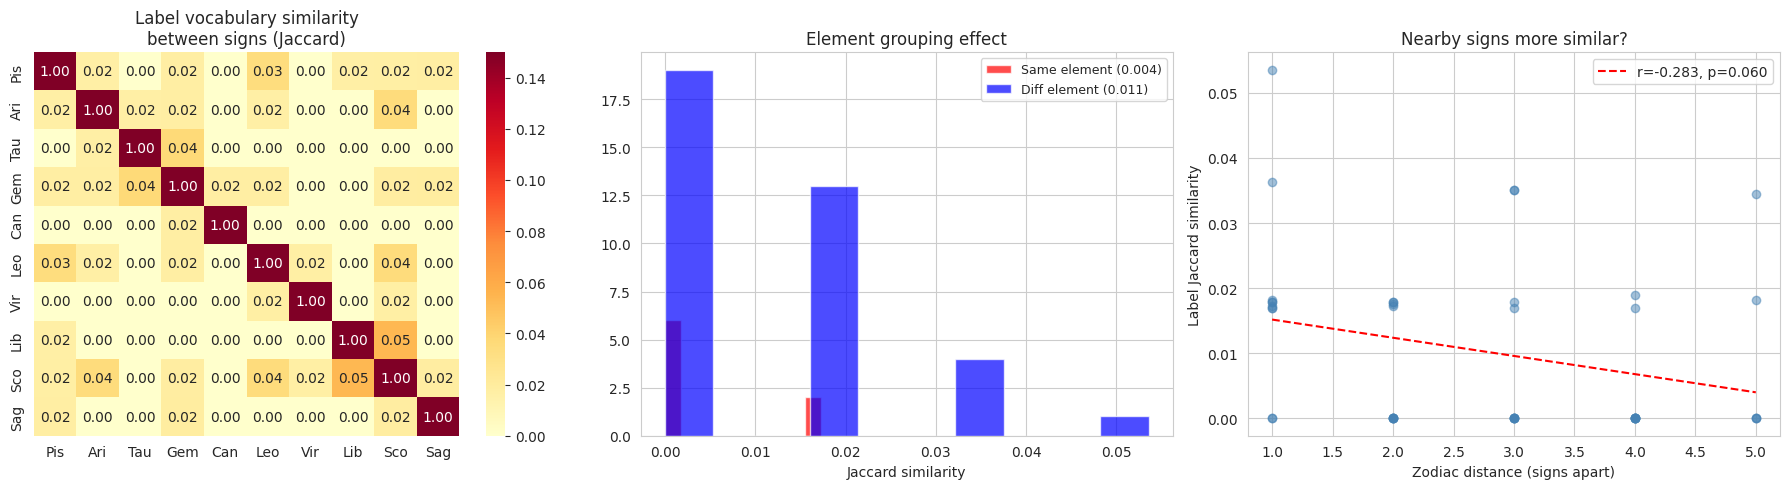

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Sign similarity matrix
sim_matrix = np.zeros((10, 10))
for p in pair_data:
    i = sign_order.index(p['s1'])
    j = sign_order.index(p['s2'])
    sim_matrix[i, j] = p['jaccard']
    sim_matrix[j, i] = p['jaccard']
np.fill_diagonal(sim_matrix, 1.0)

sns.heatmap(sim_matrix, xticklabels=[s[:3] for s in sign_order],
            yticklabels=[s[:3] for s in sign_order],
            cmap='YlOrRd', annot=True, fmt='.2f', ax=axes[0],
            vmin=0, vmax=0.15)
axes[0].set_title('Label vocabulary similarity\nbetween signs (Jaccard)')

# 2. Element vs non-element Jaccard
axes[1].hist(j_same_elem, bins=10, alpha=0.7, color='red', label=f'Same element ({np.mean(j_same_elem):.3f})')
axes[1].hist(j_diff_elem, bins=10, alpha=0.7, color='blue', label=f'Diff element ({np.mean(j_diff_elem):.3f})')
axes[1].set_xlabel('Jaccard similarity')
axes[1].set_title('Element grouping effect')
axes[1].legend(fontsize=9)

# 3. Jaccard vs zodiac distance
axes[2].scatter(dists, jaccs, alpha=0.5, color='steelblue')
# Trend line
z = np.polyfit(dists, jaccs, 1)
x_line = np.linspace(min(dists), max(dists), 50)
axes[2].plot(x_line, np.polyval(z, x_line), 'r--', label=f'r={r_dist:.3f}, p={p_dist:.3f}')
axes[2].set_xlabel('Zodiac distance (signs apart)')
axes[2].set_ylabel('Label Jaccard similarity')
axes[2].set_title('Nearby signs more similar?')
axes[2].legend()

plt.tight_layout()
plt.savefig('images/zodiac_label_analysis.png', dpi=150)
plt.show()

## Summary

In [10]:
print('=' * 65)
print('ZODIAC LABEL ANALYSIS — SUMMARY')
print('=' * 65)
print()
print('PART A — Shared labels and astrology:')
print(f'  Labels shared across signs: {len(shared)}')
print(f'  Same degree position: {same_degree}/{len(shared)}')
if degree_diffs:
    print(f'  Mean degree difference: {np.mean(degree_diffs):.1f} (random=10)')
print(f'  Element correlation: same={np.mean(j_same_elem):.4f} vs diff={np.mean(j_diff_elem):.4f}')
print(f'  Zodiac distance correlation: r={r_dist:.3f}')
print()
print('PART B — Heidelberg comparison:')
print(f'  Voynich label capacity: ~{max(effective_bits, np.mean(atoms_per_label)*3):.0f} bits')
print(f'  Compatible with: Andalo-type categories (~6 bits)')
print(f'  NOT compatible with: full Heidelberg entries (~139 bits)')
print()
print('CONCLUSION:')
print('  Each Voynich zodiac label most likely encodes a small set of')
print('  categorical properties per degree (like Andalo di Negro\'s')
print('  masculine/feminine, bright/dark, etc.), NOT a full description')
print('  with planetary positions (like the Heidelberg Astrolabium).')
print('  The visual format (nymphs in circles) resembles the Astrolabium')
print('  tradition, but the information content is closer to Andalo.')

results = {
    'shared_labels': len(shared),
    'same_degree_position': same_degree,
    'mean_degree_diff': round(float(np.mean(degree_diffs)), 1) if degree_diffs else None,
    'element_jaccard_same': round(float(np.mean(j_same_elem)), 4),
    'element_jaccard_diff': round(float(np.mean(j_diff_elem)), 4),
    'zodiac_distance_corr': round(float(r_dist), 3),
    'zodiac_distance_p': round(float(p_dist), 4),
    'label_bits': round(float(max(effective_bits, np.mean(atoms_per_label)*3)), 0),
    'compatible_with': 'Andalo di Negro degree categories (~6 bits)',
    'not_compatible_with': 'Heidelberg Astrolabium full entries (~139 bits)'
}
with open('resultados/zodiac_label_analysis_resultados.json', 'w') as f:
    json.dump(results, f, indent=2)
print('\nResults saved.')

ZODIAC LABEL ANALYSIS — SUMMARY

PART A — Shared labels and astrology:
  Labels shared across signs: 17
  Same degree position: 0/17
  Mean degree difference: 10.6 (random=10)
  Element correlation: same=0.0043 vs diff=0.0115
  Zodiac distance correlation: r=-0.283

PART B — Heidelberg comparison:
  Voynich label capacity: ~20 bits
  Compatible with: Andalo-type categories (~6 bits)
  NOT compatible with: full Heidelberg entries (~139 bits)

CONCLUSION:
  Each Voynich zodiac label most likely encodes a small set of
  categorical properties per degree (like Andalo di Negro's
  masculine/feminine, bright/dark, etc.), NOT a full description
  with planetary positions (like the Heidelberg Astrolabium).
  The visual format (nymphs in circles) resembles the Astrolabium
  tradition, but the information content is closer to Andalo.

Results saved.
